# Milestone 3 — Storage vs. Reconstruction Error

Quantify the trade-off between image quality and storage.

In [8]:
import os
if not os.path.exists("/content/svd-image-compression"):
    !git clone -q https://github.com/billygoattrain/svd-image-compression.git /content/svd-image-compression
%cd /content/svd-image-compression

/content/svd-image-compression


In [9]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("No personal photo yet: add data/my_photo.png before final submission.")

## Storage and ratio

In [10]:
A=data.camera().astype(float);m,n=A.shape
for k in [1,10,50,100,255,256]: print(k,storage(m,n,k),round(compression_ratio(m,n,k),3))
print("Largest k saving values:",(m*n-1)//(m+n+1))
print("Largest k saving float64 bytes against uint8 pixels:",(m*n-1)//(8*(m+n+1)))

1 1025 255.75
10 10250 25.575
50 51250 5.115
100 102500 2.558
255 261375 1.003
256 262400 0.999
Largest k saving values: 255
Largest k saving float64 bytes against uint8 pixels: 31


A rank-k factorization stores k(m+n+1) floating-point values; actual bytes can differ.

## Error prediction

In [11]:
s=np.linalg.svd(A,compute_uv=False)
for k in [1,5,20,50,100]:
  Ak=rank_k_approx(A,k)
  print(f"k={k}: measured={rel_error(A,Ak):.4f}, predicted={predicted_error(s,k):.4f}")
print("Energy check",np.isclose(np.linalg.norm(A)**2,np.sum(s**2)))

k=1: measured=0.3604, predicted=0.3604
k=5: measured=0.1720, predicted=0.1720
k=20: measured=0.1012, predicted=0.1012
k=50: measured=0.0636, predicted=0.0636
k=100: measured=0.0393, predicted=0.0393
Energy check True


Eckart–Young predicts best rank-k Frobenius error from discarded singular values.

## Error vs compression figure

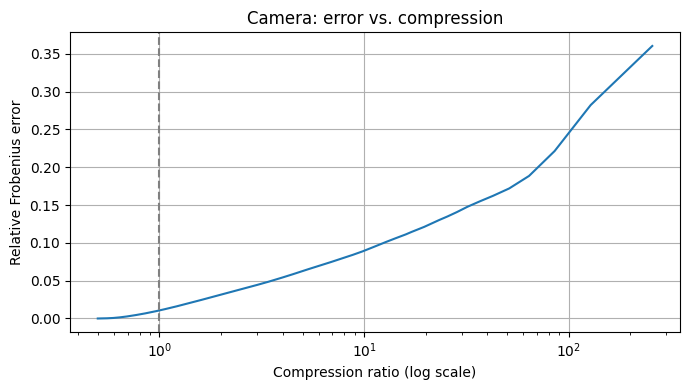

In [12]:
ks=np.arange(1,len(s)+1)
errs=np.array([predicted_error(s,int(k)) for k in ks])
ratios=np.array([compression_ratio(m,n,int(k)) for k in ks])
plt.figure(figsize=(7,4));plt.semilogx(ratios,errs);plt.axvline(1,linestyle="--",color="gray")
plt.xlabel("Compression ratio (log scale)");plt.ylabel("Relative Frobenius error")
plt.title("Camera: error vs. compression");plt.grid(True);plt.tight_layout()
plt.savefig(project_root/"figures"/"error_vs_ratio.png",dpi=150);plt.show()

The dashed line marks the point where factor storage equals pixel-count storage.

## Clipping and personal photograph

In [13]:
A20=rank_k_approx(A,20)
print("Out-of-range pixels",((A20<0)|(A20>255)).sum())
print("Error before and after clipping",rel_error(A,A20),rel_error(A,np.clip(A20,0,255)))
if P is not None:
    sp=np.linalg.svd(P,compute_uv=False)
    print("Personal image shape and k for 10% error",P.shape,k_for_error(sp,0.1))

Out-of-range pixels 2634
Error before and after clipping 0.10120775682772729 0.10083571385013855
Personal image shape and k for 10% error (800, 600) 17


For valid original pixels, clipping an approximation to [0,255] cannot increase per-pixel absolute error. Personal-photo analysis requires the actual asset.

## Part E — Find the smallest rank for target error

For each threshold, identify the **smallest** rank that reaches it. These errors are computed from singular values without reconstructing every image.

In [14]:
ks = np.arange(1, len(s)+1)
target_errors = np.array([predicted_error(s, int(k)) for k in ks])
for target in [0.10, 0.05, 0.02, 0.01]:
    k = int(ks[target_errors <= target][0])
    print(f"target={target:.0%} rank={k} error={predicted_error(s,k):.5f} ratio={compression_ratio(m,n,k):.2f}x")

target=10% rank=21 error=0.09884 ratio=12.18x
target=5% rank=73 error=0.04957 ratio=3.50x
target=2% rank=186 error=0.01984 ratio=1.38x
target=1% rank=263 error=0.00995 ratio=0.97x


## Part F — Compare the camera and text images

The two images have different shapes and singular-value patterns. Comparing relative error against rank and compression ratio helps us see why the same rank can preserve different amounts of detail.

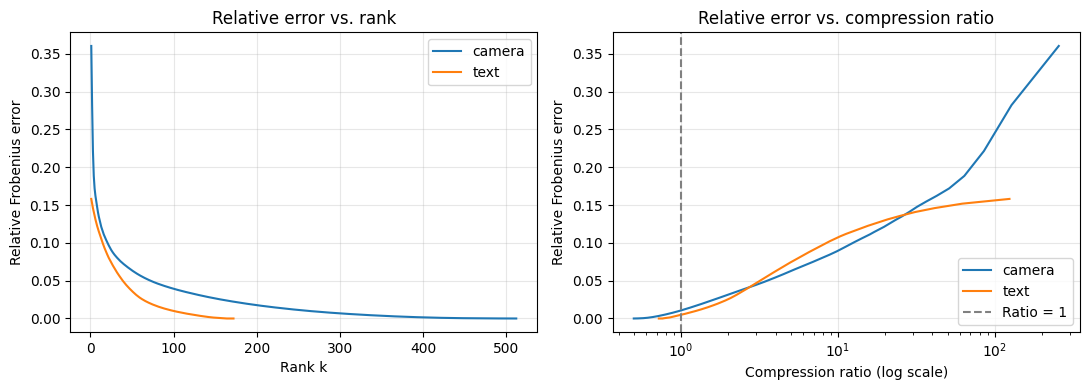

In [15]:
T = data.text().astype(float)
images = {"camera": A, "text": T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
    h, w = M.shape
    sv = np.linalg.svd(M, compute_uv=False)
    ranks = np.arange(1, len(sv)+1)
    errs = [predicted_error(sv,int(k)) for k in ranks]
    ratios = [compression_ratio(h,w,int(k)) for k in ranks]
    ax1.plot(ranks, errs, label=name)
    ax2.semilogx(ratios, errs, label=name)
ax1.set(title="Relative error vs. rank", xlabel="Rank k", ylabel="Relative Frobenius error")
ax2.set(title="Relative error vs. compression ratio", xlabel="Compression ratio (log scale)", ylabel="Relative Frobenius error")
ax2.axvline(1, color="gray", linestyle="--", label="Ratio = 1")
for ax in (ax1,ax2):
    ax.grid(True, alpha=.3)
    ax.legend()
plt.tight_layout()
plt.savefig(project_root/"figures"/"error_vs_ratio.png",dpi=150)
plt.show()

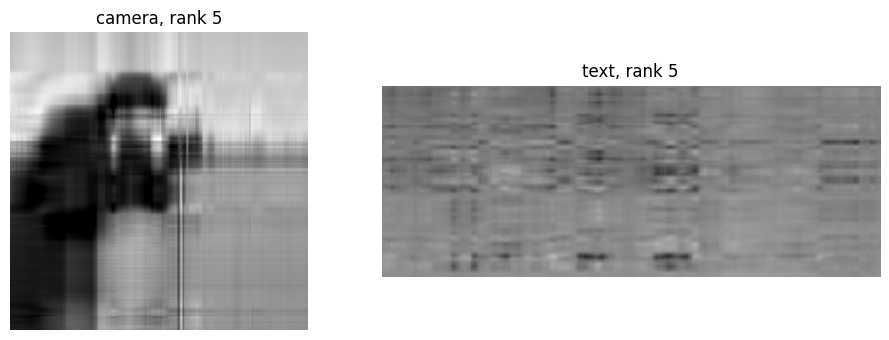

In [16]:
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax, (name, M) in zip(axes, images.items()):
    ax.imshow(np.clip(rank_k_approx(M,5),0,255),cmap="gray",vmin=0,vmax=255)
    ax.set_title(f"{name}, rank 5")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Part H — Personal photograph compression curve and selected rank

Use the photograph in `data/my_photo.png`, compare its theoretical compression ratio with relative reconstruction error, and display the original next to a compressed version. The 10% target is a starting point; visual readability should also inform your choice.

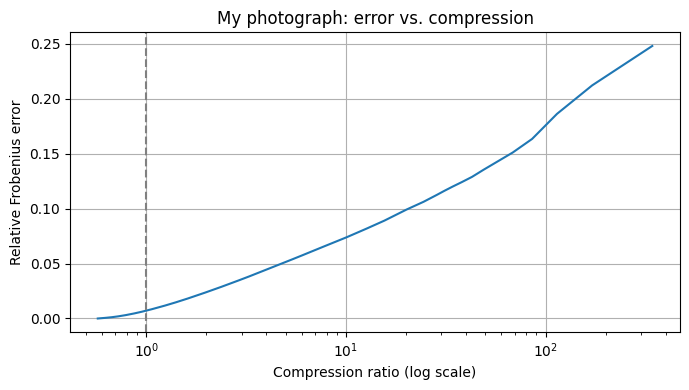

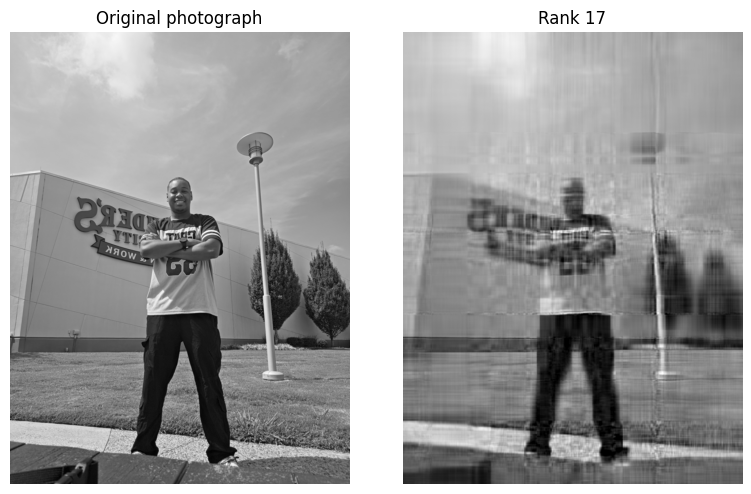

Selected rank=17, predicted error=9.9167%, ratio=20.15x
Clipped display error: 0.09899378780458924


In [17]:
assert P is not None, "Personal photo must exist at data/my_photo.png"
sp = np.linalg.svd(P, compute_uv=False)
kp = np.arange(1,len(sp)+1)
ep = [predicted_error(sp,int(k)) for k in kp]
mp, npix = P.shape
rp = [compression_ratio(mp,npix,int(k)) for k in kp]
plt.figure(figsize=(7,4))
plt.semilogx(rp,ep)
plt.axvline(1,color="gray",linestyle="--")
plt.xlabel("Compression ratio (log scale)")
plt.ylabel("Relative Frobenius error")
plt.title("My photograph: error vs. compression")
plt.grid(True)
plt.tight_layout()
plt.show()
chosen_k = k_for_error(sp,0.10)
P_compressed = np.clip(rank_k_approx(P,chosen_k),0,255)
fig, axes = plt.subplots(1,2,figsize=(8,5))
for ax, M, title in zip(axes,[P,P_compressed],["Original photograph",f"Rank {chosen_k}"]):
    ax.imshow(M,cmap="gray",vmin=0,vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Selected rank={chosen_k}, predicted error={predicted_error(sp,chosen_k):.4%}, ratio={compression_ratio(mp,npix,chosen_k):.2f}x")
print("Clipped display error:",rel_error(P,P_compressed))

## Practice Exercise 1 — When does SVD stop saving values or bytes?

A rank-k approximation stores `k(m+n+1)` values instead of `mn`. Strict value savings require `k(m+n+1) < mn`, so the greatest eligible integer is `(mn-1)//(m+n+1)`. For original uint8 pixels versus float64 SVD values, multiply the SVD value count by 8 to compare bytes.

In [18]:
for name,M in {"camera":A,"text":T}.items():
    h,w=M.shape
    print(name,"shape",M.shape,"largest k saving values",(h*w-1)//(h+w+1),"largest k saving float64 bytes",(h*w-1)//(8*(h+w+1)))
U_check, s_check, Vt_check = np.linalg.svd(A,full_matrices=False)
print("U dtype and itemsize:",U_check.dtype,U_check.itemsize)

camera shape (512, 512) largest k saving values 255 largest k saving float64 bytes 31
text shape (172, 448) largest k saving values 124 largest k saving float64 bytes 15
U dtype and itemsize: float64 8


## Practice Exercise 2 — Why can singular values predict relative error?

Eckart–Young gives the optimal rank-k Frobenius residual as the square root of the sum of squared **discarded** singular values. The full image's squared Frobenius norm equals the sum of squares of **all** singular values. Dividing gives the relative error.

In [19]:
print("Squared image norm",np.linalg.norm(A)**2)
print("Sum of squared singular values",np.sum(s**2))
print("Energy identity verified:",np.isclose(np.linalg.norm(A)**2,np.sum(s**2)))

Squared image norm 5788200983.000001
Sum of squared singular values 5788200983.000001
Energy identity verified: True


## Practice Exercise 3 — Numerical error versus text readability

Background pixels can dominate the Frobenius error even when letters blur enough to become unreadable. Consider measuring edge contrast or asking a reader to transcribe the compressed text in addition to reporting the relative error.

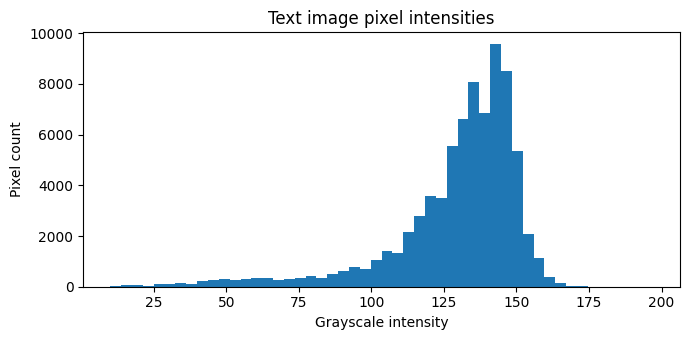

Most common intensity bin: 140.9 to 144.6 (9555 pixels)


In [20]:
plt.figure(figsize=(7,3.5))
plt.hist(T.ravel(),bins=50)
plt.title("Text image pixel intensities")
plt.xlabel("Grayscale intensity")
plt.ylabel("Pixel count")
plt.tight_layout()
plt.show()
counts, edges = np.histogram(T.ravel(),bins=50)
j = int(np.argmax(counts))
print(f"Most common intensity bin: {edges[j]:.1f} to {edges[j+1]:.1f} ({counts[j]} pixels)")

## Practice Exercise 4 — Compare all three images at 10% error

Whichever image has the largest ratio at the *same* error tolerance requires the fewest stored SVD values relative to its original size. Concentration of energy among leading singular values helps explain that difference.

In [21]:
comparisons = {}
for name,M in {"camera":A,"text":T,"my photograph":P}.items():
    values = np.linalg.svd(M,compute_uv=False)
    k = k_for_error(values,0.10)
    ratio = compression_ratio(*M.shape,k)
    comparisons[name] = ratio
    print(f"{name:14s}: k={k}, error={predicted_error(values,k):.4%}, ratio={ratio:.2f}x")
print("Largest ratio:",max(comparisons,key=comparisons.get))

camera        : k=21, error=9.8837%, ratio=12.18x
text          : k=15, error=9.8929%, ratio=8.27x
my photograph : k=17, error=9.9167%, ratio=20.15x
Largest ratio: my photograph


## Practice Exercise 5 — Why clipping cannot increase error

For a true pixel `a` in [0,255]: if `x < 0`, replacing x by 0 moves it closer to a; if `0 <= x <= 255`, x stays unchanged; and if `x > 255`, replacing x by 255 also moves it closer to a. Each pixel's squared error therefore cannot increase. Summing squared errors and taking a square root proves the Frobenius error cannot increase.

In [22]:
truth_pixels=np.array([100.,100.,100.])
estimated_pixels=np.array([-10.,125.,300.])
print("Before clipping:",np.abs(estimated_pixels-truth_pixels))
print("After clipping: ",np.abs(np.clip(estimated_pixels,0,255)-truth_pixels))

Before clipping: [110.  25. 200.]
After clipping:  [100.  25. 155.]


## Practice Exercise 6 — Which rank would you share?

The smallest rank with no more than 10% relative error is a reproducible starting choice. Compare it visually with both lower and higher ranks; if crucial details are too blurry, use a higher k. State the numerical trade-off and the visual reason for your preferred rank in your own words.

In [23]:
for k in [max(1,chosen_k//2),chosen_k,min(chosen_k*2,min(P.shape))]:
    print(f"k={k:3d} predicted error={predicted_error(sp,k):.2%} compression={compression_ratio(mp,npix,k):.2f}x")

k=  8 predicted error=12.88% compression=42.83x
k= 17 predicted error=9.92% compression=20.15x
k= 34 predicted error=7.39% compression=10.08x


### What we found

This milestone helped me understand the trade-off between image quality and compression using SVD. Increasing the rank reduced reconstruction error, but it also required storing more numerical values.

For the camera image, rank 21 achieved approximately 9.88% relative error with a theoretical compression ratio of 12.18×. My personal photograph achieved approximately 9.92% error at rank 17, with a compression ratio of 20.15×. The printed text image achieved approximately 9.89% error at rank 15, with a ratio of 8.27×.

Although rank 17 met the 10% error target for my photograph, the compressed image was noticeably blurry. I would consider a higher rank if preserving facial details were important.

I also observed that clipping reconstructed pixel values to the range 0–255 slightly reduced the error. These results demonstrate that SVD can reduce the number of values needed to represent an image, although theoretical compression does not necessarily equal real file-size savings.